импорты и настройки проекта

In [7]:
# Работа с файлами и папками
from pathlib import Path

# Работа с массивами
import numpy as np

# Визуализация изображений
import matplotlib.pyplot as plt

# PyTorch
import torch
import torchvision

# Датасет с изображениями кошек и собак
from torchvision.datasets import OxfordIIITPet

# Фиксируем случайность для воспроизводимости результатов
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

# Проверяем доступность GPU
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Определяем папку проекта
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "lab3":
    PROJECT_DIR = CURRENT_DIR
elif (CURRENT_DIR / "lab3").exists():
    PROJECT_DIR = CURRENT_DIR / "lab3"
else:
    PROJECT_DIR = CURRENT_DIR

# Папки проекта
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

# Создаём необходимые папки
for folder in [DATA_DIR, RESULTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Папки для собственных тестовых изображений
(DATA_DIR / "test" / "cats").mkdir(parents=True, exist_ok=True)
(DATA_DIR / "test" / "dogs").mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Устройство:", DEVICE)
print("Папка проекта:", PROJECT_DIR)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Устройство: cuda
Папка проекта: c:\Users\agrim\_WORKDIR_\Master\thirdSem\cv\lab3


загрузка Oxford-IIIT Pet

In [8]:
# Загружаем обучающую часть датасета
dataset = OxfordIIITPet(
    root=str(DATA_DIR),
    split="trainval",
    target_types="binary-category",
    download=True
)

# Выводим информацию о датасете
print("Датасет успешно загружен!")
print("Количество изображений:", len(dataset))

# Получаем первое изображение
image, label = dataset[0]

print("\nИнформация о первом изображении:")
print("Размер изображения:", image.size)
print("Метка класса:", label)

# Выводим названия классов, если они доступны
if hasattr(dataset, "bin_classes"):
    print("Названия классов:", dataset.bin_classes)

Датасет успешно загружен!
Количество изображений: 3680

Информация о первом изображении:
Размер изображения: (394, 500)
Метка класса: 0
Названия классов: ['Cat', 'Dog']


разделение датасета

In [9]:
# Импортируем функцию разделения датасета
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# Получаем метки всех изображений
all_labels = []

for i in tqdm(range(len(dataset)), desc="Проверяем метки"):

    # Нам нужна только метка, само изображение не сохраняем
    _, label = dataset[i]

    all_labels.append(int(label))

# Преобразуем список в массив NumPy
all_labels = np.array(all_labels)

# Создаём список индексов изображений
all_indices = np.arange(len(dataset))

# Разделяем данные на обучающую и валидационную выборки
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=SEED,
    stratify=all_labels
)

# Считаем количество кошек и собак
train_counts = np.bincount(
    all_labels[train_indices],
    minlength=2
)

val_counts = np.bincount(
    all_labels[val_indices],
    minlength=2
)

# Выводим результаты
print("Обучающая выборка:")
print("Кошки:", train_counts[0])
print("Собаки:", train_counts[1])

print("\nВалидационная выборка:")
print("Кошки:", val_counts[0])
print("Собаки:", val_counts[1])

# Рассчитываем веса классов для будущей функции потерь
class_weights = len(train_indices) / (2 * train_counts)

CLASS_WEIGHTS = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("\nВеса классов:", CLASS_WEIGHTS)

c:\Users\agrim\_WORKDIR_\Master\thirdSem\cv\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Проверяем метки: 100%|██████████| 3680/3680 [00:21<00:00, 172.74it/s]


Обучающая выборка:
Кошки: 950
Собаки: 1994

Валидационная выборка:
Кошки: 238
Собаки: 498

Веса классов: tensor([1.5495, 0.7382], device='cuda:0')


визуализация примеров

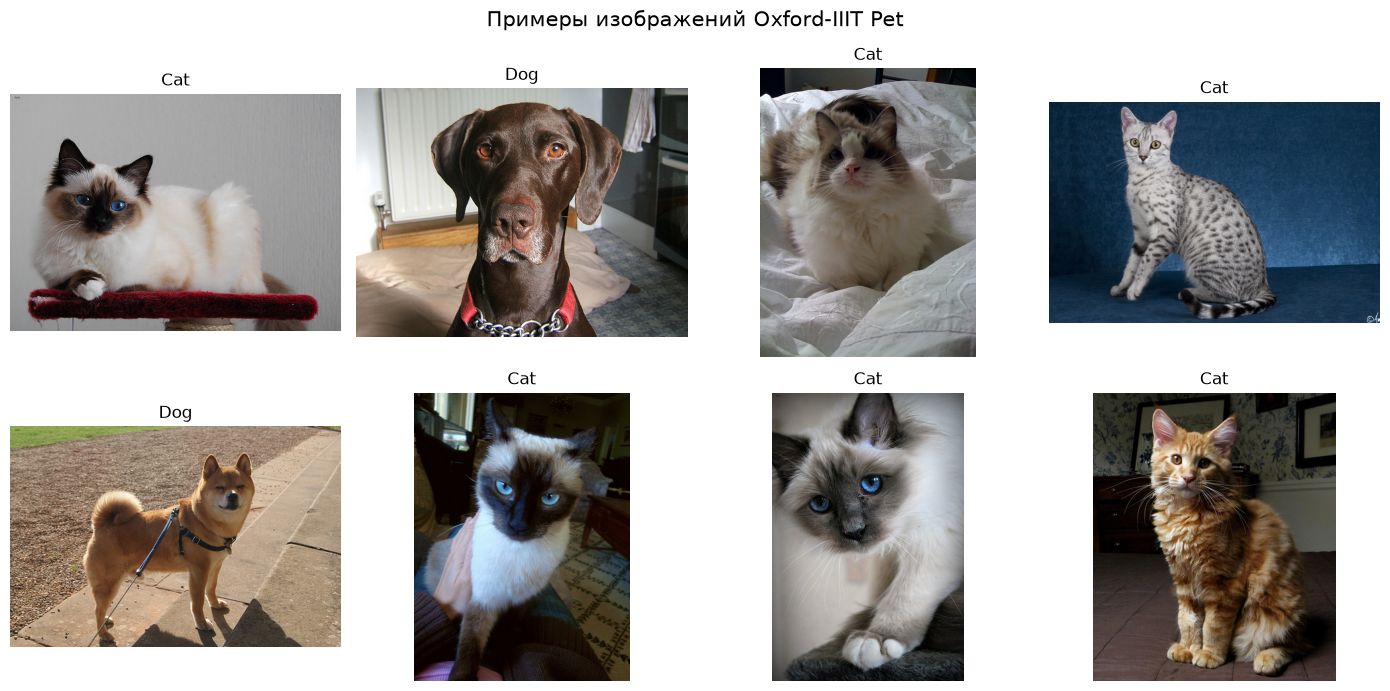

In [10]:
# Выбираем 8 случайных изображений
rng = np.random.default_rng(SEED)

sample_indices = rng.choice(
    len(dataset),
    size=8,
    replace=False
)

# Создаём сетку из 8 изображений
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

# Получаем названия бинарных классов
class_names = getattr(dataset, "bin_classes", ["Cat", "Dog"])

for ax, idx in zip(axes.flat, sample_indices):

    # Получаем изображение и его метку
    image, label = dataset[int(idx)]

    # Показываем изображение
    ax.imshow(image)

    # Подписываем класс
    label = int(label)

    if 0 <= label < len(class_names):
        class_name = class_names[label]
    else:
        class_name = f"Class {label}"

    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Примеры изображений Oxford-IIIT Pet", fontsize=15)

plt.tight_layout()

# Сохраняем график
plt.savefig(
    RESULTS_DIR / "dataset_examples.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Создаём преобразования изображений

In [15]:
# Импортируем преобразования изображений
from torchvision import transforms

# Стандартные параметры нормализации ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# Преобразования для обучающей выборки
train_transform = transforms.Compose([

    # Случайно обрезаем изображение и меняем его размер
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),

    # С вероятностью 50% отражаем изображение по горизонтали
    transforms.RandomHorizontalFlip(p=0.5),

    # Немного поворачиваем изображение
    transforms.RandomRotation(10, fill=(124, 116, 104)),

    # Преобразуем изображение в тензор PyTorch
    transforms.ToTensor(),

    # Нормализуем значения пикселей
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])


# Преобразования для валидационной выборки
val_transform = transforms.Compose([

    # Меняем размер изображения
    transforms.Resize(256),

    # Вырезаем центральную область 224x224
    transforms.CenterCrop(224),

    # Преобразуем изображение в тензор
    transforms.ToTensor(),

    # Нормализуем изображение
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Преобразования изображений созданы!")

Преобразования изображений созданы!


Создаём Dataset и DataLoader

In [16]:
# Импортируем необходимые классы
from torch.utils.data import DataLoader, Subset

# Создаём обучающий датасет
train_base = OxfordIIITPet(
    root=str(DATA_DIR),
    split="trainval",
    target_types="binary-category",
    transform=train_transform,
    download=False
)

# Создаём валидационный датасет
val_base = OxfordIIITPet(
    root=str(DATA_DIR),
    split="trainval",
    target_types="binary-category",
    transform=val_transform,
    download=False
)

# Выбираем нужные индексы для каждой выборки
train_dataset = Subset(train_base, train_indices)
val_dataset = Subset(val_base, val_indices)


# Размер одного пакета изображений
BATCH_SIZE = 32

# Создаём загрузчик обучающих данных
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# Создаём загрузчик валидационных данных
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("DataLoader успешно создан!")
print("Обучающих изображений:", len(train_dataset))
print("Валидационных изображений:", len(val_dataset))

print("Пакетов для обучения:", len(train_loader))
print("Пакетов для валидации:", len(val_loader))

DataLoader успешно создан!
Обучающих изображений: 2944
Валидационных изображений: 736
Пакетов для обучения: 92
Пакетов для валидации: 23


Проверяем DataLoader

In [17]:
# Получаем первый пакет изображений
images, labels = next(iter(train_loader))

# Выводим информацию
print("Размер пакета изображений:", images.shape)
print("Размер пакета меток:", labels.shape)

print("\nУстройство:", DEVICE)

print("Минимальное значение пикселя:", images.min().item())
print("Максимальное значение пикселя:", images.max().item())

Размер пакета изображений: torch.Size([32, 3, 224, 224])
Размер пакета меток: torch.Size([32])

Устройство: cuda
Минимальное значение пикселя: -2.1179039478302
Максимальное значение пикселя: 2.640000104904175


Визуализируем подготовленные изображения

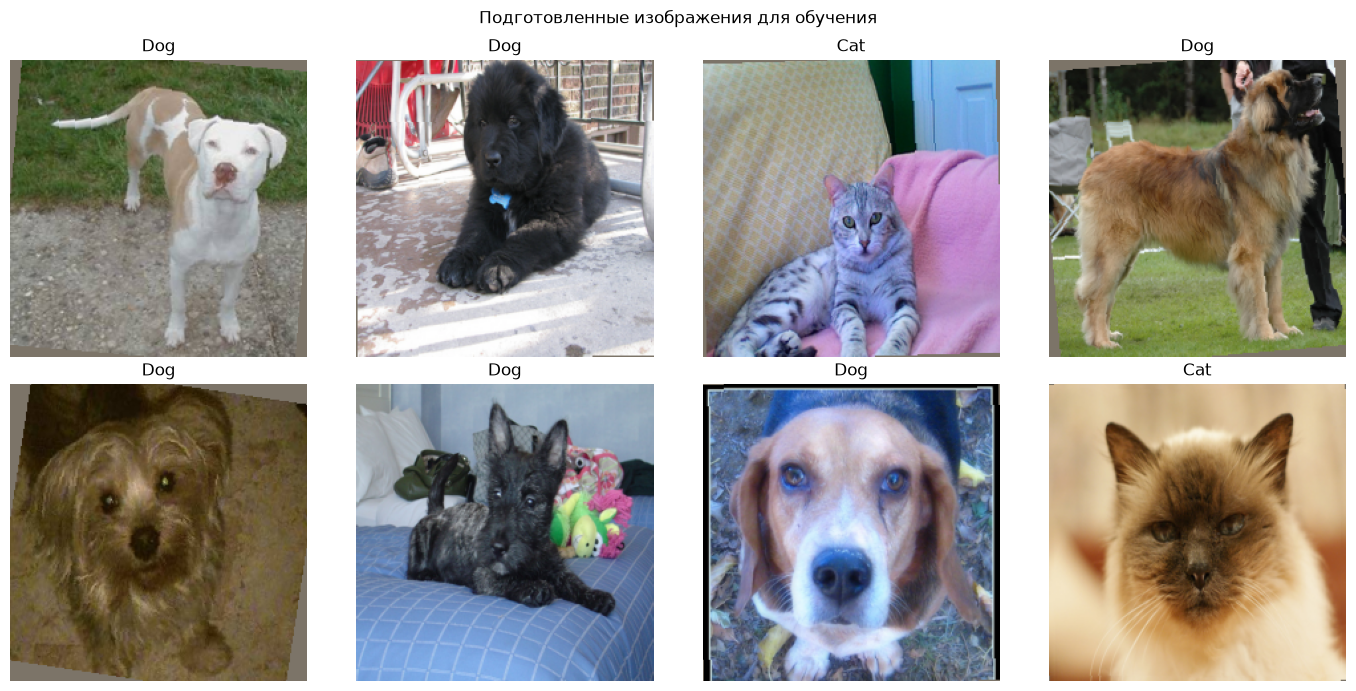

In [18]:
# Создаём обратные параметры нормализации
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

# Создаём область для 8 изображений
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

# Названия классов
class_names = ["Cat", "Dog"]

for i, ax in enumerate(axes.flat):

    # Берём изображение из пакета
    image = images[i].cpu()

    # Отменяем нормализацию для отображения
    image = image * std + mean

    # Ограничиваем значения от 0 до 1
    image = image.clamp(0, 1)

    # Показываем изображение
    ax.imshow(image.permute(1, 2, 0))

    # Подписываем класс
    ax.set_title(class_names[labels[i].item()])

    ax.axis("off")

plt.suptitle("Подготовленные изображения для обучения")

plt.tight_layout()

# Сохраняем результат
plt.savefig(
    RESULTS_DIR / "prepared_images.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

загрузка MobileNetV3-Small

In [19]:
# Импортируем необходимые компоненты
import torch.nn as nn
from torchvision import models

# Загружаем MobileNetV3-Small с предобученными весами ImageNet
weights = models.MobileNet_V3_Small_Weights.DEFAULT

model = models.mobilenet_v3_small(
    weights=weights
)

print("Модель успешно загружена!")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\agrim/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:01<00:00, 8.18MB/s]


Модель успешно загружена!


Замораживаем слои извлечения признаков

In [20]:
# Замораживаем слои извлечения признаков
for param in model.features.parameters():

    param.requires_grad = False

print("Слои извлечения признаков заморожены!")

Слои извлечения признаков заморожены!


Заменяем классификатор

In [21]:
# Получаем количество входных признаков последнего слоя
in_features = model.classifier[-1].in_features

# Заменяем последний слой на классификатор с двумя выходами
model.classifier[-1] = nn.Linear(
    in_features,
    2
)

# Переносим модель на видеокарту
model = model.to(DEVICE)

print("Классификатор успешно заменён!")
print("Количество классов:", 2)

Классификатор успешно заменён!
Количество классов: 2


Проверяем количество параметров

In [22]:
# Считаем общее количество параметров
total_params = sum(
    param.numel()
    for param in model.parameters()
)

# Считаем количество обучаемых параметров
trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

print("Общее количество параметров:", total_params)

print("Обучаемых параметров:", trainable_params)

print(
    "Замороженных параметров:",
    total_params - trainable_params
)

Общее количество параметров: 1519906
Обучаемых параметров: 592898
Замороженных параметров: 927008


Проверяем работу модели

In [23]:
# Переключаем модель в режим проверки
model.eval()

# Получаем один пакет изображений
images, labels = next(iter(train_loader))

# Переносим изображения на видеокарту
images = images.to(DEVICE)

# Отключаем вычисление градиентов
with torch.no_grad():

    # Получаем предсказания нейросети
    outputs = model(images)

# Выводим размеры результатов
print("Размер входных данных:", images.shape)

print("Размер выходных данных:", outputs.shape)

# Показываем результаты для первого изображения
print("\nПредсказание для первого изображения:")
print(outputs[0])

Размер входных данных: torch.Size([32, 3, 224, 224])
Размер выходных данных: torch.Size([32, 2])

Предсказание для первого изображения:
tensor([-0.9405,  0.0465], device='cuda:0')


Настраиваем функцию потерь

In [24]:
# Функция потерь для классификации
criterion = nn.CrossEntropyLoss(
    weight=CLASS_WEIGHTS
)

print("Функция потерь создана!")

Функция потерь создана!


Создаём оптимизатор

In [25]:
# Создаём оптимизатор AdamW
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=0.0001
)

print("Оптимизатор создан!")

Оптимизатор создан!


Настраиваем параметры обучения

In [26]:
# Количество эпох обучения
EPOCHS = 10

# Планировщик скорости обучения
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# Словарь для сохранения результатов обучения
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

# Лучшая точность на валидационной выборке
best_val_accuracy = 0.0

# Путь для сохранения лучшей модели
MODEL_PATH = MODELS_DIR / "mobilenet_v3_small_best.pth"

print("Настройки обучения готовы!")

Настройки обучения готовы!


Функция обучения одной эпохи

In [27]:
def train_one_epoch():

    # Переводим модель в режим обучения
    model.train()

    # Замороженную часть оставляем в режиме оценки,
    # чтобы BatchNorm не изменял свои статистики
    model.features.eval()

    # Счётчики ошибок и правильных ответов
    total_loss = 0
    correct = 0
    total = 0

    # Перебираем все пакеты изображений
    for images, labels in tqdm(train_loader, desc="Обучение", leave=False):

        # Переносим данные на видеокарту
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        # Обнуляем старые градиенты
        optimizer.zero_grad()

        # Получаем предсказания нейросети
        outputs = model(images)

        # Рассчитываем ошибку
        loss = criterion(outputs, labels)

        # Вычисляем градиенты
        loss.backward()

        # Обновляем веса нейросети
        optimizer.step()

        # Сохраняем значение ошибки
        total_loss += loss.item() * images.size(0)

        # Получаем предсказанные классы
        predictions = outputs.argmax(dim=1)

        # Считаем правильные предсказания
        correct += (predictions == labels).sum().item()

        # Общее количество изображений
        total += labels.size(0)

    # Рассчитываем среднюю ошибку
    average_loss = total_loss / total

    # Рассчитываем точность
    accuracy = correct / total

    return average_loss, accuracy

Функция проверки качества

In [28]:
def validate():

    # Переводим модель в режим оценки
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    # Отключаем вычисление градиентов
    with torch.no_grad():

        # Перебираем валидационные данные
        for images, labels in val_loader:

            # Переносим данные на видеокарту
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            # Получаем предсказания
            outputs = model(images)

            # Рассчитываем ошибку
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            # Определяем предсказанные классы
            predictions = outputs.argmax(dim=1)

            # Считаем правильные ответы
            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    # Рассчитываем среднюю ошибку
    average_loss = total_loss / total

    # Рассчитываем точность
    accuracy = correct / total

    return average_loss, accuracy

Запускаем обучение

In [29]:
# Запускаем обучение
for epoch in range(EPOCHS):

    print(f"\nЭпоха {epoch + 1}/{EPOCHS}")

    # Обучаем модель
    train_loss, train_accuracy = train_one_epoch()

    # Проверяем модель
    val_loss, val_accuracy = validate()

    # Обновляем скорость обучения
    scheduler.step(val_accuracy)

    # Сохраняем историю обучения
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Получаем текущую скорость обучения
    current_lr = optimizer.param_groups[0]["lr"]

    # Сохраняем модель, если точность улучшилась
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch + 1,
                "val_accuracy": val_accuracy
            },
            MODEL_PATH
        )

        print("Найдена новая лучшая модель!")

    # Выводим результаты эпохи
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy * 100:.2f}%")

    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy * 100:.2f}%")

    print(f"Learning Rate: {current_lr:.6f}")


# Загружаем лучшую модель
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

print("\nОбучение завершено!")
print("Лучшая эпоха:", checkpoint["epoch"])
print(f"Лучшая точность: {checkpoint['val_accuracy'] * 100:.2f}%")
print("Модель сохранена:", MODEL_PATH)


Эпоха 1/10


Найдена новая лучшая модель!
Train Loss: 0.1278
Train Accuracy: 94.57%
Val Loss: 0.0398
Val Accuracy: 98.23%
Learning Rate: 0.001000

Эпоха 2/10


Найдена новая лучшая модель!
Train Loss: 0.0587
Train Accuracy: 97.52%
Val Loss: 0.0373
Val Accuracy: 98.91%
Learning Rate: 0.001000

Эпоха 3/10


Train Loss: 0.0453
Train Accuracy: 98.20%
Val Loss: 0.0292
Val Accuracy: 98.78%
Learning Rate: 0.001000

Эпоха 4/10


Train Loss: 0.0377
Train Accuracy: 98.68%
Val Loss: 0.0392
Val Accuracy: 98.91%
Learning Rate: 0.001000

Эпоха 5/10


Найдена новая лучшая модель!
Train Loss: 0.0438
Train Accuracy: 98.30%
Val Loss: 0.0230
Val Accuracy: 99.18%
Learning Rate: 0.001000

Эпоха 6/10


Train Loss: 0.0403
Train Accuracy: 98.51%
Val Loss: 0.0243
Val Accuracy: 99.05%
Learning Rate: 0.001000

Эпоха 7/10


Найдена новая лучшая модель!
Train Loss: 0.0200
Train Accuracy: 99.05%
Val Loss: 0.0191
Val Accuracy: 99.32%
Learning Rate: 0.001000

Эпоха 8/10


Train Loss: 0.0118
Train Accuracy: 99.63%
Val Loss: 0.0197
Val Accuracy: 99.18%
Learning Rate: 0.001000

Эпоха 9/10


Train Loss: 0.0110
Train Accuracy: 99.73%
Val Loss: 0.0206
Val Accuracy: 98.91%
Learning Rate: 0.001000

Эпоха 10/10


Train Loss: 0.0212
Train Accuracy: 99.22%
Val Loss: 0.0209
Val Accuracy: 99.32%
Learning Rate: 0.000500

Обучение завершено!
Лучшая эпоха: 7
Лучшая точность: 99.32%
Модель сохранена: c:\Users\agrim\_WORKDIR_\Master\thirdSem\cv\lab3\models\mobilenet_v3_small_best.pth


Строим графики обучения

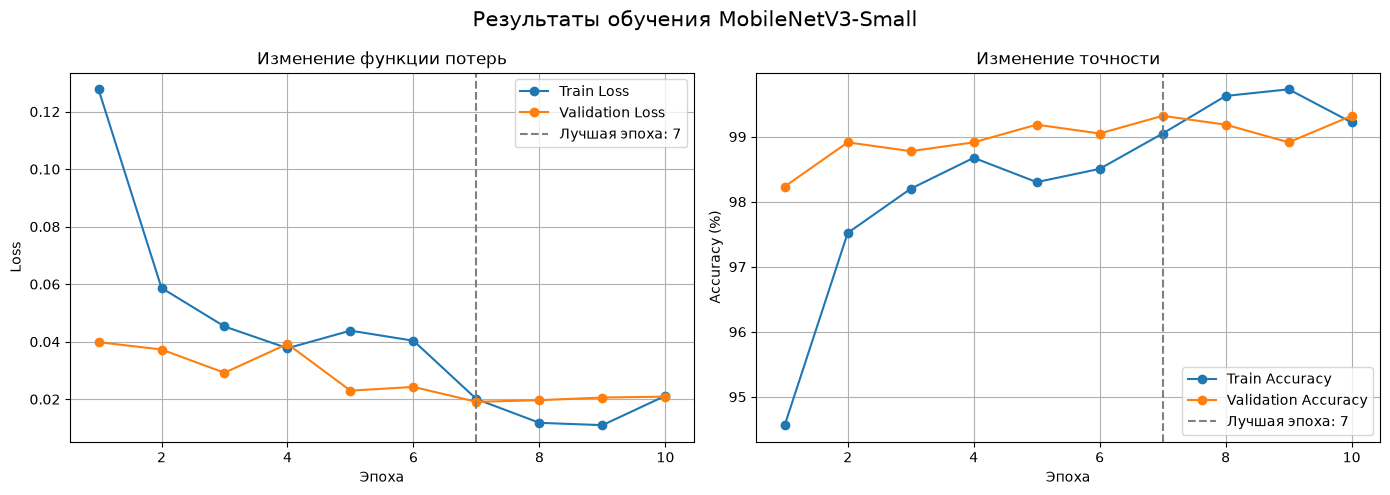

In [30]:
# Создаём список эпох
epochs = range(1, len(history["train_loss"]) + 1)

# Номер лучшей эпохи
best_epoch = checkpoint["epoch"]

# Создаём область для двух графиков
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Первый график — Loss
axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    color="gray",
    label=f"Лучшая эпоха: {best_epoch}"
)

axes[0].set_title("Изменение функции потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


# Второй график — Accuracy
axes[1].plot(
    epochs,
    [x * 100 for x in history["train_accuracy"]],
    marker="o",
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    [x * 100 for x in history["val_accuracy"]],
    marker="o",
    label="Validation Accuracy"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    color="gray",
    label=f"Лучшая эпоха: {best_epoch}"
)

axes[1].set_title("Изменение точности")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)


# Общий заголовок
plt.suptitle("Результаты обучения MobileNetV3-Small", fontsize=15)

plt.tight_layout()

# Сохраняем графики
plt.savefig(
    RESULTS_DIR / "training_history.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Получаем предсказания модели

In [31]:
# Импортируем необходимые метрики
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Переводим модель в режим оценки
model.eval()

# Списки для сохранения результатов
all_predictions = []
all_labels_true = []

# Отключаем вычисление градиентов
with torch.no_grad():

    # Перебираем валидационную выборку
    for images, labels in val_loader:

        # Переносим изображения на GPU
        images = images.to(DEVICE)

        # Получаем предсказания
        outputs = model(images)

        # Определяем предсказанный класс
        predictions = outputs.argmax(dim=1)

        # Сохраняем результаты
        all_predictions.extend(predictions.cpu().numpy())
        all_labels_true.extend(labels.numpy())


# Преобразуем списки в массивы NumPy
all_predictions = np.array(all_predictions)
all_labels_true = np.array(all_labels_true)

print("Количество проверенных изображений:", len(all_labels_true))
print("Предсказания успешно получены!")

Количество проверенных изображений: 736
Предсказания успешно получены!


Рассчитываем метрики

In [32]:
# Рассчитываем общую точность
accuracy = accuracy_score(
    all_labels_true,
    all_predictions
)

# Выводим отчёт по каждому классу
print("Результаты классификации:\n")

print(
    classification_report(
        all_labels_true,
        all_predictions,
        labels=[0, 1],
        target_names=["Cat", "Dog"],
        digits=4,
        zero_division=0
    )
)

print(f"Общая Accuracy: {accuracy * 100:.2f}%")

Результаты классификации:

              precision    recall  f1-score   support

         Cat     0.9874    0.9916    0.9895       238
         Dog     0.9960    0.9940    0.9950       498

    accuracy                         0.9932       736
   macro avg     0.9917    0.9928    0.9922       736
weighted avg     0.9932    0.9932    0.9932       736

Общая Accuracy: 99.32%


Строим матрицу ошибок

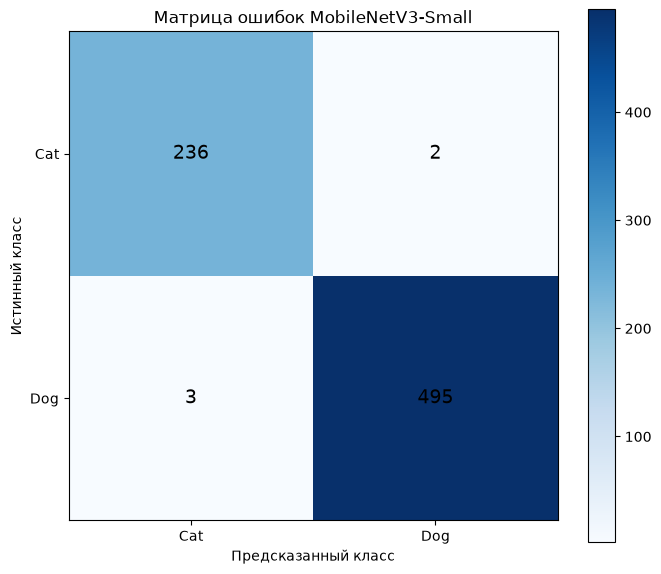

In [33]:
# Строим матрицу ошибок
cm = confusion_matrix(
    all_labels_true,
    all_predictions,
    labels=[0, 1]
)

# Создаём график
fig, ax = plt.subplots(figsize=(7, 6))

# Отображаем матрицу
im = ax.imshow(cm, cmap="Blues")

# Добавляем цветовую шкалу
plt.colorbar(im, ax=ax)

# Подписываем оси
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Cat", "Dog"])
ax.set_yticklabels(["Cat", "Dog"])

ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")

ax.set_title("Матрица ошибок MobileNetV3-Small")

# Добавляем значения в ячейки
for i in range(2):
    for j in range(2):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=14
        )

plt.tight_layout()

# Сохраняем результат
plt.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Посмотрим на ошибки нейросети

In [34]:
# Список неправильно классифицированных изображений
misclassified = []

# Переводим модель в режим оценки
model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images_gpu = images.to(DEVICE)

        # Получаем предсказания
        outputs = model(images_gpu)

        # Рассчитываем вероятности
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        # Проверяем каждое изображение
        for i in range(len(labels)):

            if predictions[i].item() != labels[i].item():

                misclassified.append({
                    "image": images[i].cpu(),
                    "true": labels[i].item(),
                    "pred": predictions[i].item(),
                    "confidence": probabilities[i].max().item()
                })


print("Количество ошибок:", len(misclassified))

Количество ошибок: 5


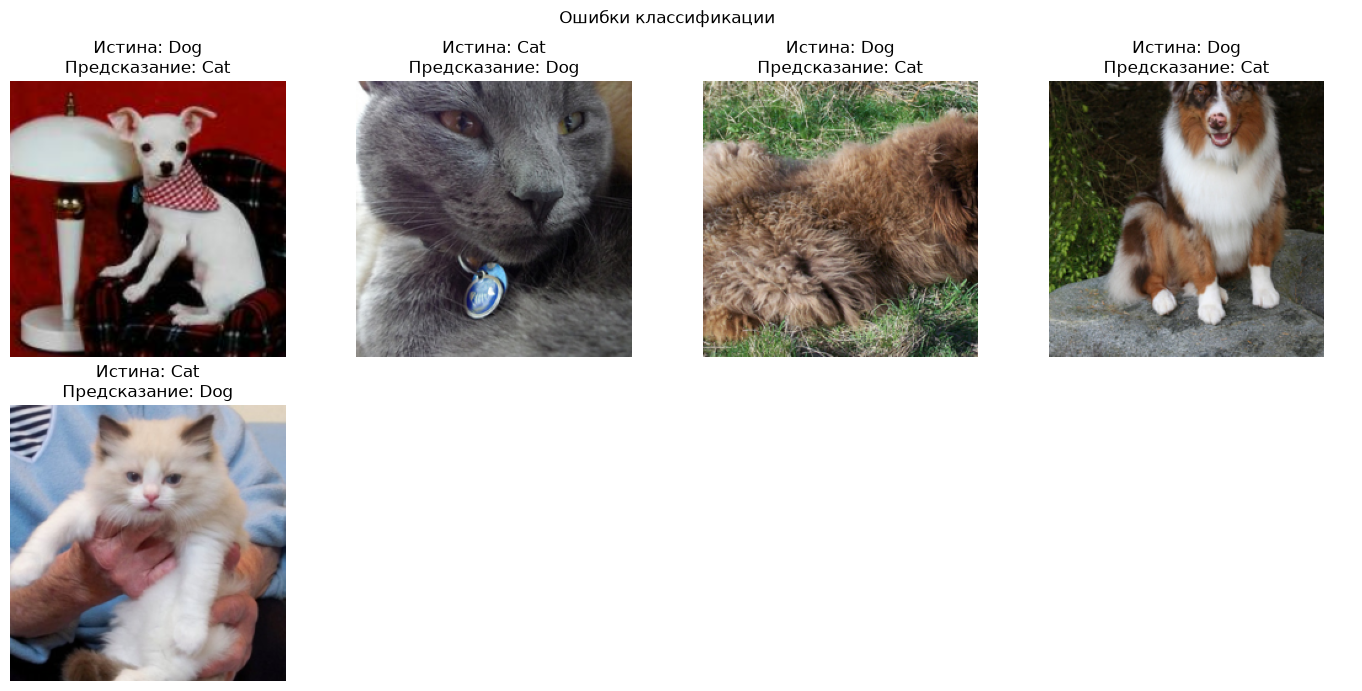

In [35]:
# Показываем до 8 ошибочных изображений
count = min(8, len(misclassified))

if count > 0:

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(14, 7)
    )

    for ax in axes.flat:
        ax.axis("off")

    for i in range(count):

        item = misclassified[i]

        # Отменяем нормализацию
        image = item["image"] * std + mean

        image = image.clamp(0, 1)

        # Показываем изображение
        axes.flat[i].imshow(image.permute(1, 2, 0))

        # Получаем названия классов
        true_class = class_names[item["true"]]
        pred_class = class_names[item["pred"]]

        axes.flat[i].set_title(
            f"Истина: {true_class}\n"
            f"Предсказание: {pred_class}"
        )

        axes.flat[i].axis("off")

    plt.suptitle("Ошибки классификации")

    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / "misclassified_images.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

else:

    print("Ошибок классификации нет!")

Проверяем фотографии

In [37]:
from pathlib import Path

# Определяем путь к тестовым изображениям
current_dir = Path.cwd()

if (current_dir / "test_images").exists():
    TEST_DIR = current_dir / "test_images"
else:
    TEST_DIR = current_dir / "lab3" / "test_images"

# Поддерживаемые форматы
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".avif"
}

# Проверяем количество фотографий
for class_name in ["cats", "dogs"]:

    class_dir = TEST_DIR / class_name

    images = [
        file for file in class_dir.rglob("*")
        if file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(f"{class_name}: {len(images)} изображений")

print("\nПроверка завершена!")
print("Путь:", TEST_DIR.resolve())

cats: 25 изображений
dogs: 25 изображений

Проверка завершена!
Путь: C:\Users\agrim\_WORKDIR_\Master\thirdSem\cv\lab3\test_images


Загружаем тестовую выборку

In [38]:
# Импортируем необходимые библиотеки
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

# Регистрируем поддержку AVIF
import pillow_avif

# Поддерживаемые форматы
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".avif"
}

# Подготовка изображений для нейросети
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Загружаем изображения из папок cats и dogs
test_dataset = ImageFolder(
    root=str(TEST_DIR),
    transform=test_transform,
    is_valid_file=lambda path: (
        Path(path).suffix.lower() in IMAGE_EXTENSIONS
    )
)

# Создаём DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Проверяем соответствие классов
print("Классы:", test_dataset.class_to_idx)

print("Всего тестовых изображений:", len(test_dataset))

print("Количество кошек:", 
      test_dataset.targets.count(0))

print("Количество собак:", 
      test_dataset.targets.count(1))

print("\nТестовая выборка успешно загружена!")

Классы: {'cats': 0, 'dogs': 1}
Всего тестовых изображений: 50
Количество кошек: 25
Количество собак: 25

Тестовая выборка успешно загружена!


Получаем предсказания нейросети

In [39]:
# Переводим модель в режим оценки
model.eval()

# Списки для сохранения результатов
test_predictions = []
test_labels = []
test_probabilities = []

# Отключаем вычисление градиентов
with torch.no_grad():

    # Перебираем тестовые изображения
    for images, labels in test_loader:

        # Переносим изображения на видеокарту
        images = images.to(DEVICE)

        # Получаем предсказания
        outputs = model(images)

        # Переводим логиты в вероятности
        probabilities = torch.softmax(outputs, dim=1)

        # Определяем предсказанный класс
        predictions = outputs.argmax(dim=1)

        # Сохраняем результаты
        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.numpy()
        )

        test_probabilities.extend(
            probabilities.cpu().numpy()
        )


# Преобразуем списки в массивы
test_predictions = np.array(test_predictions)
test_labels = np.array(test_labels)
test_probabilities = np.array(test_probabilities)

print("Классификация завершена!")
print("Обработано изображений:", len(test_predictions))

Классификация завершена!
Обработано изображений: 50


Рассчитываем метрики качества

In [40]:
# Рассчитываем Accuracy
test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

# Выводим подробный отчёт
print("Результаты тестирования:\n")

print(
    classification_report(
        test_labels,
        test_predictions,
        labels=[0, 1],
        target_names=["Cat", "Dog"],
        digits=4,
        zero_division=0
    )
)

print(
    f"Тестовая Accuracy: {test_accuracy * 100:.2f}%"
)

Результаты тестирования:

              precision    recall  f1-score   support

         Cat     0.9231    0.9600    0.9412        25
         Dog     0.9583    0.9200    0.9388        25

    accuracy                         0.9400        50
   macro avg     0.9407    0.9400    0.9400        50
weighted avg     0.9407    0.9400    0.9400        50

Тестовая Accuracy: 94.00%


Строим матрицу ошибок

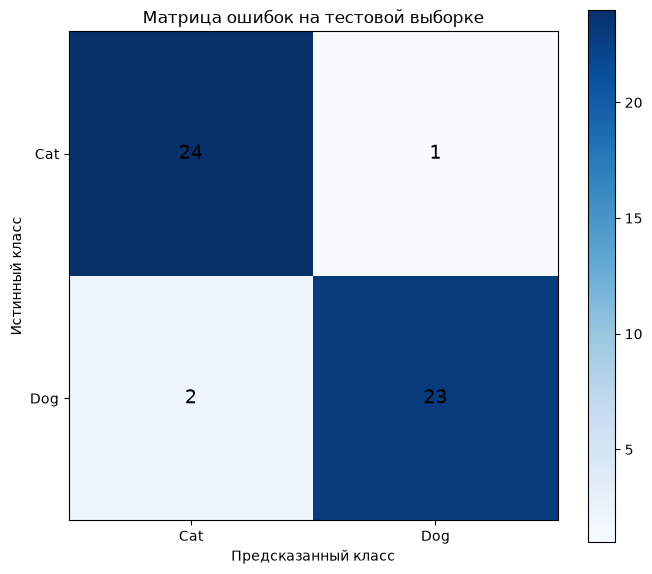

In [41]:
# Создаём матрицу ошибок
test_cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1]
)

# Создаём график
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(test_cm, cmap="Blues")

plt.colorbar(im, ax=ax)

# Подписываем оси
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Cat", "Dog"])
ax.set_yticklabels(["Cat", "Dog"])

ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")

ax.set_title("Матрица ошибок на тестовой выборке")

# Добавляем значения
for i in range(2):
    for j in range(2):

        ax.text(
            j,
            i,
            str(test_cm[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=14
        )

plt.tight_layout()

# Сохраняем график
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    RESULTS_DIR / "test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Визуализируем предсказания

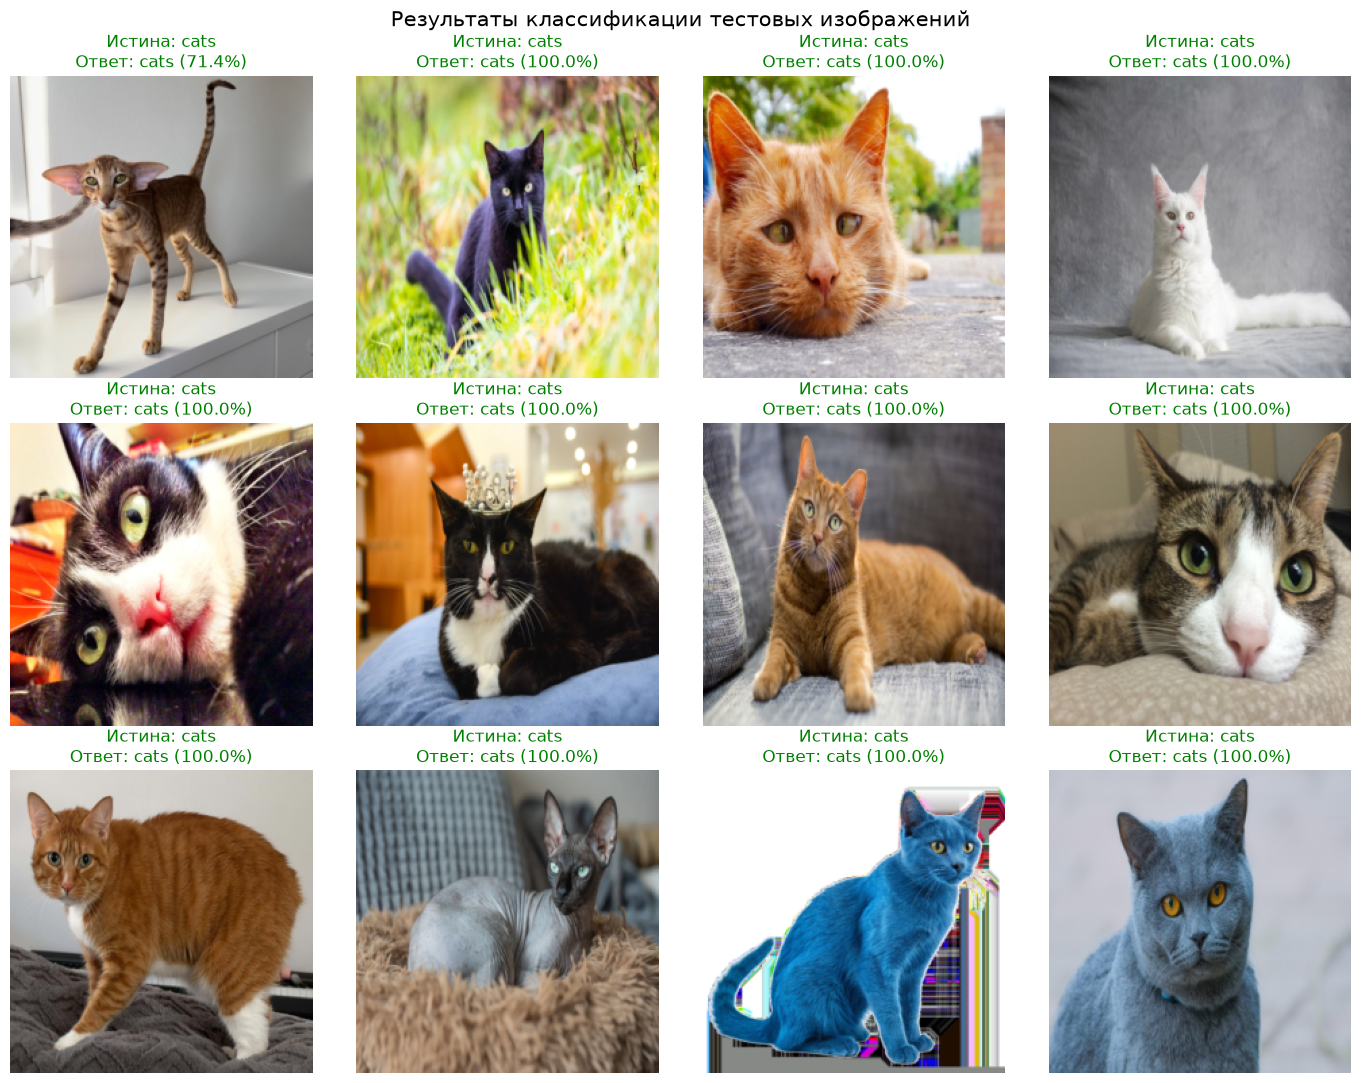

In [42]:
# Создаём область для изображений
fig, axes = plt.subplots(3, 4, figsize=(14, 11))

# Перебираем первые 12 изображений
for i, ax in enumerate(axes.flat):

    # Получаем изображение
    image, true_label = test_dataset[i]

    # Получаем предсказание
    predicted = test_predictions[i]

    # Получаем вероятность предсказанного класса
    confidence = test_probabilities[i][predicted] * 100

    # Отменяем нормализацию
    mean_tensor = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std_tensor = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    image = image * std_tensor + mean_tensor

    image = image.clamp(0, 1)

    # Преобразуем изображение для отображения
    image = image.permute(1, 2, 0)

    # Названия классов
    true_name = test_dataset.classes[true_label]
    predicted_name = test_dataset.classes[predicted]

    # Показываем изображение
    ax.imshow(image)

    # Проверяем правильность классификации
    if true_label == predicted:
        color = "green"
    else:
        color = "red"

    ax.set_title(
        f"Истина: {true_name}\n"
        f"Ответ: {predicted_name} ({confidence:.1f}%)",
        color=color
    )

    ax.axis("off")

plt.suptitle(
    "Результаты классификации тестовых изображений",
    fontsize=15
)

plt.tight_layout()

# Сохраняем результат
plt.savefig(
    RESULTS_DIR / "test_predictions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Количество ошибок: 3


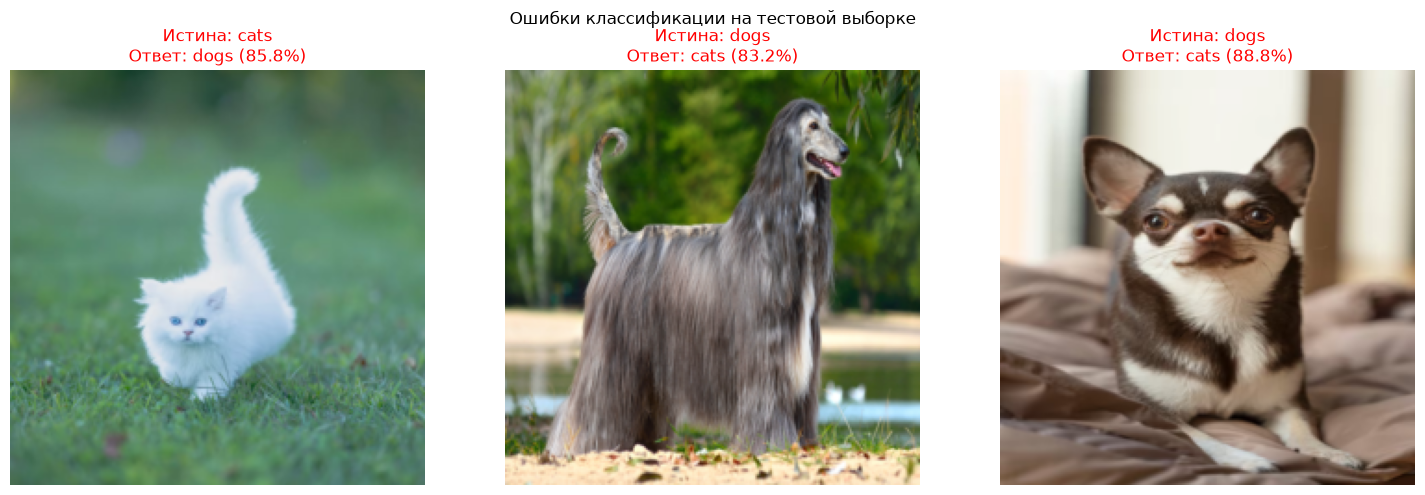

In [43]:
# Находим индексы неправильно классифицированных изображений
wrong_indices = np.where(
    test_predictions != test_labels
)[0]

print("Количество ошибок:", len(wrong_indices))

# Создаём график
fig, axes = plt.subplots(
    1,
    len(wrong_indices),
    figsize=(5 * len(wrong_indices), 5)
)

axes = np.atleast_1d(axes)

for ax, idx in zip(axes, wrong_indices):

    # Получаем изображение
    image, true_label = test_dataset[idx]

    # Отменяем нормализацию
    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    image = image * std + mean
    image = image.clamp(0, 1)
    image = image.permute(1, 2, 0)

    # Получаем названия классов
    true_name = test_dataset.classes[true_label]
    pred_name = test_dataset.classes[test_predictions[idx]]

    # Получаем уверенность модели
    confidence = test_probabilities[idx][test_predictions[idx]] * 100

    # Показываем изображение
    ax.imshow(image)

    ax.set_title(
        f"Истина: {true_name}\n"
        f"Ответ: {pred_name} ({confidence:.1f}%)",
        color="red"
    )

    ax.axis("off")

plt.suptitle("Ошибки классификации на тестовой выборке")
plt.tight_layout()

# Сохраняем график
plt.savefig(
    RESULTS_DIR / "test_misclassified_images.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()